## LOT 1 — Préparation du jeu de données Digits
**Étape 1 — Charger le dataset Digits**

In [3]:
from sklearn.datasets import load_digits

digits = load_digits()

X = digits.data
y = digits.target

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("Classes :", digits.target_names)

Dimensions de X : (1797, 64)
Dimensions de y : (1797,)
Classes : [0 1 2 3 4 5 6 7 8 9]


**Étape 2 — Examiner les images**

In [4]:
image = X[0].reshape(8, 8)
print(image)

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


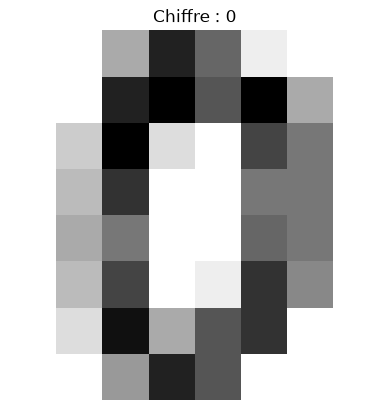

In [7]:
import matplotlib.pyplot as plt

plt.imshow(image, cmap="gray_r")
plt.title(f"Chiffre : {y[0]}")
plt.axis("off")
plt.show()

**Étape 3 — Examiner les valeurs des pixels**

In [14]:
print("Minimum :", X.min())
print("Maximum :", X.max())
print("Moyenne :", X.mean())
print("Écart-type :", X.std())

Minimum : 0.0
Maximum : 16.0
Moyenne : 4.884164579855314
Écart-type : 6.016787548672236


**Étape 4 — Identifier les pixels constants**

In [21]:
import numpy as np

In [22]:
variance = np.var(X, axis=0)
pixels_constants = np.where(variance == 0)[0]
print("Nombre de pixels constants :", len(pixels_constants))
print("Indices :", pixels_constants)

Nombre de pixels constants : 3
Indices : [ 0 32 39]


**Étape 5 — Séparer Train et Test**

In [28]:
from sklearn.model_selection import train_test_split

In [29]:
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42,stratify=y)

**Étape 6 — Centrer les données**

In [33]:
mu = np.mean(X_train, axis=0)
X_train_center = X_train - mu
X_test_center = X_test - mu

In [35]:
print("Moyenne avant centrage :", X_train.mean())
print("Moyenne après centrage :", X_train_center.mean())

print("Shape X_train_c :", X_train_center.shape)
print("Shape X_test_c :", X_test_center.shape)

Moyenne avant centrage : 4.895093945720251
Moyenne après centrage : 8.127728753692864e-17
Shape X_train_c : (1437, 64)
Shape X_test_c : (360, 64)


**Étape 7 — Étudier la standardisation**

In [36]:
sigma = np.std(X_train, axis=0)
sigma_safe = np.where(sigma == 0, 1, sigma)
X_train_std = (X_train - mu) / sigma_safe
X_test_std = (X_test - mu) / sigma_safe

In [38]:
print("Shape :", X_train_std.shape)
print("Moyenne globale :", X_train_std.mean())
print("Écart-type global :", X_train_std.std())

mask = sigma > 0

print("Moyennes par pixel :",
      X_train_std.mean(axis=0)[mask][:6])

print("Écarts-types par pixel :",
      X_train_std.std(axis=0)[mask][:5])

Shape : (1437, 64)
Moyenne globale : 8.498575693024858e-18
Écart-type global : 0.9762812094883324
Moyennes par pixel : [-2.60519975e-16 -4.01364552e-17  1.51429167e-16  2.99111235e-16
 -2.54957271e-17  1.29410130e-17]
Écarts-types par pixel : [1. 1. 1. 1. 1.]


 ## comparaison entre centrage et standaisatio

## LOT 2 — Démonstrations mathématiques